In [1]:

import pandas as pd
import requests

# Delhi location
latitude = 28.6139
longitude = 77.2090

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": "1940-01-01",
    "end_date": "2025-12-31",
    "daily": [
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "wind_speed_10m_mean",
        "pressure_msl_mean"
    ],
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params, timeout=180)
response.raise_for_status()

weather_data = response.json()

# Convert daily observations into a DataFrame
df = pd.DataFrame(weather_data["daily"])
df = df.rename(columns={
    "time": "date",
    "temperature_2m_mean": "meantemp",
    "relative_humidity_2m_mean": "humidity",
    "wind_speed_10m_mean": "wind_speed",
    "pressure_msl_mean": "meanpressure"
})

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# Save the downloaded dataset
df.to_csv("Delhi_Daily_Weather.csv", index=False)

print("Dataset shape:", df.shape)
print("Total records:", len(df))
print("Start date:", df["date"].min())
print("End date:", df["date"].max())
print("\nMissing values:")
print(df.isnull().sum())
print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (31412, 5)
Total records: 31412
Start date: 1940-01-01 00:00:00
End date: 2025-12-31 00:00:00

Missing values:
date            0
meantemp        1
humidity        1
wind_speed      1
meanpressure    1
dtype: int64

First 5 rows:


,date,meantemp,humidity,wind_speed,meanpressure
0,1940-01-01,NaN,NaN,NaN,NaN
1,1940-01-02,15.4,22.0,8.8,1019.2
2,1940-01-03,15.2,17.0,10.2,1019.8
3,1940-01-04,15.1,13.0,11.2,1017.6
4,1940-01-05,15.2,14.0,9.3,1017.2


In [2]:

# Check dataset size and date coverage
print("Before cleaning:", df.shape)
print("Total records:", len(df))
print("Date range:", df["date"].min(), "to", df["date"].max())

# Count missing values in each column
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Remove duplicate dates, if any
df = df.drop_duplicates(subset=["date"])

# Sort dates chronologically
df = df.sort_values("date").reset_index(drop=True)

# Convert weather columns to numeric values
weather_cols = [
    "meantemp", "humidity", "wind_speed", "meanpressure"
]

df[weather_cols] = df[weather_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Fill missing weather values using time interpolation
df = df.set_index("date")
df[weather_cols] = df[weather_cols].interpolate(
    method="time", limit_area="inside"
)
df = df.reset_index()

# Remove any rows still missing required values
df = df.dropna(subset=weather_cols).reset_index(drop=True)

print("\nAfter cleaning:", df.shape)
print("Remaining records:", len(df))
print("Remaining missing values:")
print(df.isnull().sum())
print("\nFirst 5 cleaned rows:")
display(df.head())


Before cleaning: (31412, 5)
Total records: 31412
Date range: 1940-01-01 00:00:00 to 2025-12-31 00:00:00

Missing values before cleaning:
date            0
meantemp        1
humidity        1
wind_speed      1
meanpressure    1
dtype: int64

After cleaning: (31411, 5)
Remaining records: 31411
Remaining missing values:
date            0
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64

First 5 cleaned rows:


,date,meantemp,humidity,wind_speed,meanpressure
0,1940-01-02,15.4,22.0,8.8,1019.2
1,1940-01-03,15.2,17.0,10.2,1019.8
2,1940-01-04,15.1,13.0,11.2,1017.6
3,1940-01-05,15.2,14.0,9.3,1017.2
4,1940-01-06,15.1,15.0,9.7,1016.1


In [3]:

print("Total records:", len(df))
print("Total columns:", len(df.columns))

print("\nDate range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate dates:", df["date"].duplicated().sum())

# Check whether the minimum requirement is satisfied
if len(df) >= 15000:
    print("\nSUCCESS: Minimum 15,000 records requirement satisfied!")
else:
    print("\nWARNING: Dataset has fewer than 15,000 records.")


Total records: 31411
Total columns: 5

Date range:
Start: 1940-01-02 00:00:00
End: 2025-12-31 00:00:00

Missing values:
date            0
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64

Duplicate dates: 0

SUCCESS: Minimum 15,000 records requirement satisfied!


In [4]:

from sklearn.preprocessing import MinMaxScaler

# Ensure dates are sorted
df = df.sort_values("date").reset_index(drop=True)

# Select input features
feature_cols = [
    "meantemp",
    "humidity",
    "wind_speed",
    "meanpressure"
]

# Chronological split: 70%, 15%, 15%
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nTraining dates:",
      train_df["date"].min(), "to", train_df["date"].max())
print("Validation dates:",
      val_df["date"].min(), "to", val_df["date"].max())
print("Testing dates:",
      test_df["date"].min(), "to", test_df["date"].max())

# Fit scaler ONLY on training data
scaler = MinMaxScaler()
scaler.fit(train_df[feature_cols])

# Transform all sets using the training-fitted scaler
train_scaled = scaler.transform(train_df[feature_cols])
val_scaled = scaler.transform(val_df[feature_cols])
test_scaled = scaler.transform(test_df[feature_cols])

print("\nScaled training shape:", train_scaled.shape)
print("Scaled validation shape:", val_scaled.shape)
print("Scaled testing shape:", test_scaled.shape)


Training records: 21987
Validation records: 4712
Testing records: 4712

Training dates: 1940-01-02 00:00:00 to 2000-03-13 00:00:00
Validation dates: 2000-03-14 00:00:00 to 2013-02-05 00:00:00
Testing dates: 2013-02-06 00:00:00 to 2025-12-31 00:00:00

Scaled training shape: (21987, 4)
Scaled validation shape: (4712, 4)
Scaled testing shape: (4712, 4)


In [5]:

import numpy as np

# Use previous 30 days to predict the next day's temperature
LOOKBACK = 30

# Temperature is the first column in feature_cols
TEMP_INDEX = feature_cols.index("meantemp")

def create_sequences(data, lookback=30):
    X, y = [], []

    for i in range(lookback, len(data)):
        # Previous 30 days, all 4 weather features
        X.append(data[i - lookback:i, :])

        # Next day's mean temperature
        y.append(data[i, TEMP_INDEX])

    return np.array(X), np.array(y)

# Training sequences
X_train, y_train = create_sequences(train_scaled, LOOKBACK)

# Validation: include preceding 30 training days as context
val_context = np.vstack([
    train_scaled[-LOOKBACK:],
    val_scaled
])
X_val, y_val = create_sequences(val_context, LOOKBACK)

# Testing: include preceding 30 days from before test starts
test_context = np.vstack([
    val_scaled[-LOOKBACK:],
    test_scaled
])
X_test, y_test = create_sequences(test_context, LOOKBACK)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (21957, 30, 4)
y_train: (21957,)
X_val: (4712, 30, 4)
y_val: (4712,)
X_test: (4712, 30, 4)
y_test: (4712,)


In [6]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducible results
tf.keras.utils.set_random_seed(42)

# Build the LSTM model
model = Sequential([
    Input(shape=(30, 4)),
    LSTM(64),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,777 (77.25 KB)

 Trainable params: 19,777 (77.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)


Epoch 1/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - loss: 0.0109 - mae: 0.0715 - val_loss: 0.0031 - val_mae: 0.0449
Epoch 2/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.0037 - mae: 0.0476 - val_loss: 0.0020 - val_mae: 0.0354
Epoch 3/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - loss: 0.0030 - mae: 0.0423 - val_loss: 0.0018 - val_mae: 0.0326
Epoch 4/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - loss: 0.0026 - mae: 0.0393 - val_loss: 0.0017 - val_mae: 0.0322
Epoch 5/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0022 - mae: 0.0369 - val_loss: 0.0014 - val_mae: 0.0292
Epoch 6/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0021 - mae: 0.0355 - val_loss: 0.0015 - val_mae: 0.0305
Epoch 7/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0019 - mae: 0.0332 - val_loss: 0.0012 - val_mae: 0.0265
Epoch 8/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0017 - mae: 0.0322 - val_loss: 0.0012 - val_mae: 0.0271
Epoch 9/30
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 21

In [8]:

print("Training stopped at epoch:",
      len(history.history["loss"]))

print("Best validation loss:",
      min(history.history["val_loss"]))

print("Best epoch:",
      np.argmin(history.history["val_loss"]) + 1)

# Evaluate on the unseen test set
test_loss, test_mae_scaled = model.evaluate(
    X_test, y_test, verbose=0
)

print("Normalized test loss:", test_loss)
print("Normalized test MAE:", test_mae_scaled)


Training stopped at epoch: 16
Best validation loss: 0.0009646193357184529
Best epoch: 11
Normalized test loss: 0.001062379451468587
Normalized test MAE: 0.02491879276931286


Test MAE: 0.815 °C
Test RMSE: 1.066 °C


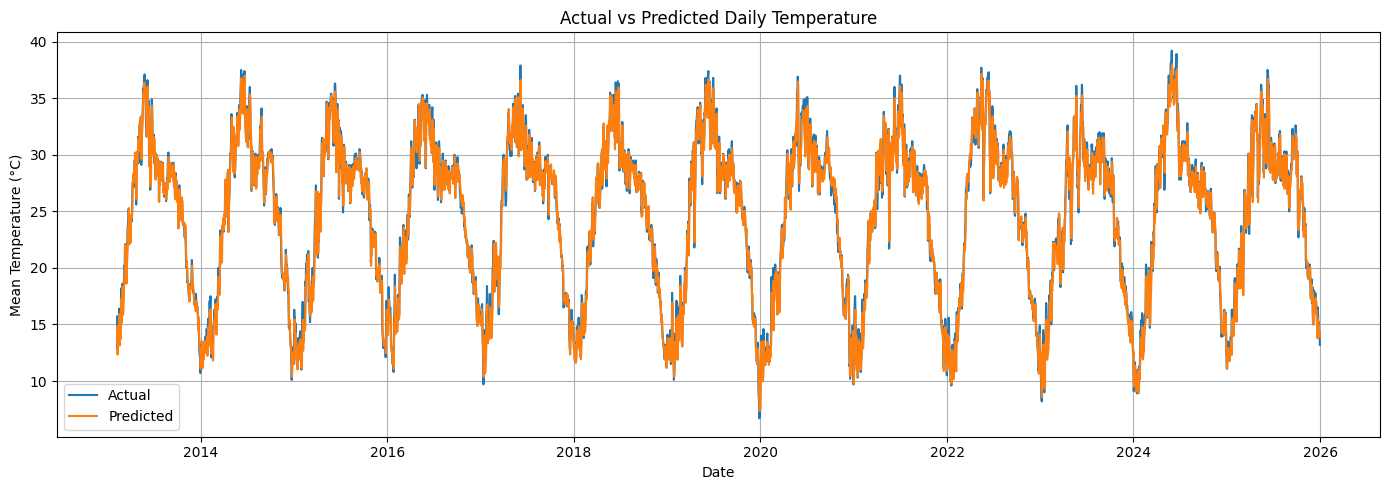

In [9]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Predict temperatures on the test set
y_pred_scaled = model.predict(X_test, verbose=0)

# Convert scaled temperature values back to Celsius
def inverse_temperature(values):
    values = np.asarray(values).reshape(-1)
    dummy = np.zeros((len(values), len(feature_cols)))
    dummy[:, TEMP_INDEX] = values
    return scaler.inverse_transform(dummy)[:, TEMP_INDEX]

y_actual = inverse_temperature(y_test)
y_predicted = inverse_temperature(y_pred_scaled)

# Evaluation metrics in Celsius
mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print(f"Test MAE: {mae:.3f} °C")
print(f"Test RMSE: {rmse:.3f} °C")

# Actual vs predicted graph
plt.figure(figsize=(14, 5))
plt.plot(test_df["date"], y_actual, label="Actual")
plt.plot(test_df["date"], y_predicted, label="Predicted")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.title("Actual vs Predicted Daily Temperature")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [10]:

# Use the latest 30 available weather observations
last_30_days = df[feature_cols].tail(30)

# Scale using the scaler fitted on training data
last_30_scaled = scaler.transform(last_30_days)

# LSTM expects: (samples, timesteps, features)
latest_sequence = last_30_scaled.reshape(1, 30, 4)

# Predict next-day mean temperature
next_day_scaled = model.predict(latest_sequence, verbose=0)

# Convert prediction back to Celsius
next_day_temp = inverse_temperature(next_day_scaled)[0]

last_date = df["date"].max()
forecast_date = last_date + pd.Timedelta(days=1)

print("Last observed date:", last_date.date())
print("Forecast date:", forecast_date.date())
print(f"Predicted mean temperature: {next_day_temp:.2f} °C")


Last observed date: 2025-12-31
Forecast date: 2026-01-01
Predicted mean temperature: 12.86 °C
